### Importância das Variáveis

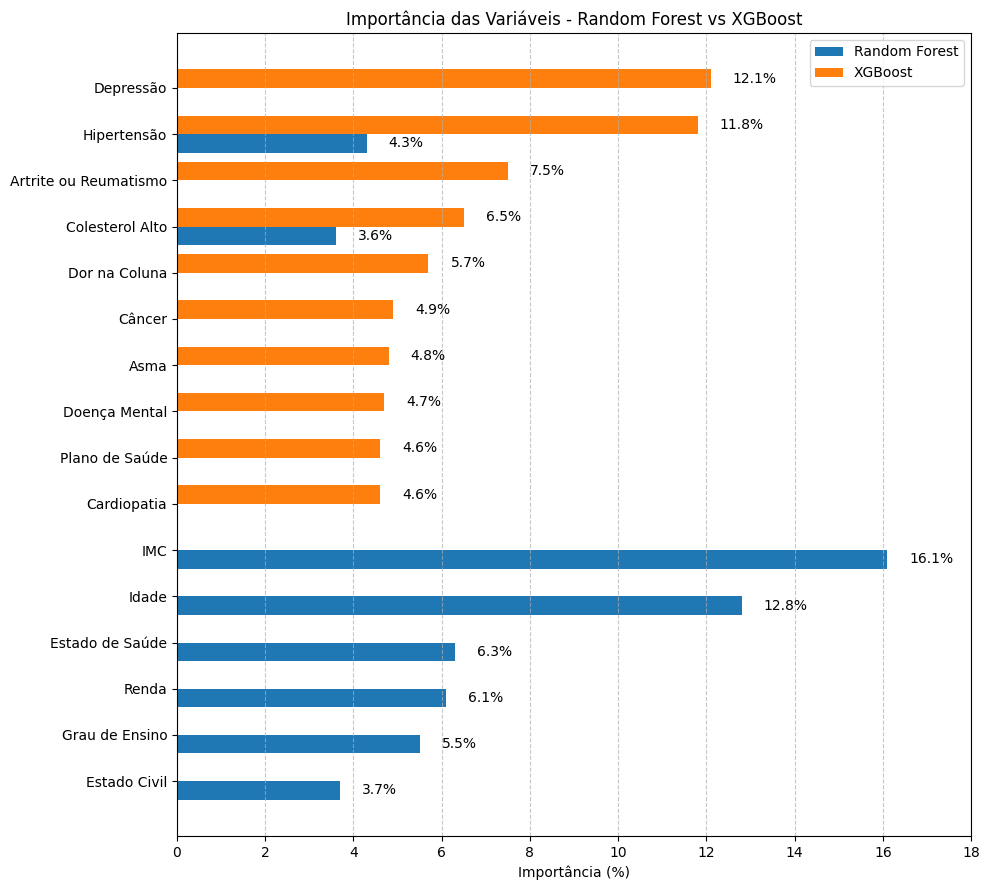

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Dados da tabela
data = {
    "Variável": [
        "Depressão", "Hipertensão", "Artrite ou Reumatismo", "Colesterol Alto", "Dor na Coluna",
        "Câncer", "Asma", "Doença Mental", "Plano de Saúde", "Cardiopatia", "IMC", "Idade",
        "Estado de Saúde", "Renda", "Grau de Ensino", "Estado Civil"
    ],
    "XGBoost (%)": [12.1, 11.8, 7.5, 6.5, 5.7, 4.9, 4.8, 4.7, 4.6, 4.6, None, None, None, None, None, None],
    "Random Forest (%)": [None, 4.3, None, 3.6, None, None, None, None, None, None, 16.1, 12.8, 6.3, 6.1, 5.5, 3.7]
}

df = pd.DataFrame(data)

# Criação do gráfico com novas cores
fig, ax = plt.subplots(figsize=(10, 9))
bar_width = 0.4
y_pos = range(len(df))

# Barras com novas cores
rf_bars = ax.barh([y + bar_width/2 for y in y_pos], df["Random Forest (%)"], height=bar_width, label="Random Forest", color="#1f77b4")
xgb_bars = ax.barh([y - bar_width/2 for y in y_pos], df["XGBoost (%)"], height=bar_width, label="XGBoost", color="#ff7f0e")

# Anotação dos valores nas barras
for bar in rf_bars:
    if bar.get_width():
        ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2, f'{bar.get_width():.1f}%', va='center')

for bar in xgb_bars:
    if bar.get_width():
        ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2, f'{bar.get_width():.1f}%', va='center')

# Eixos
ax.set_yticks(y_pos)
ax.set_yticklabels(df["Variável"])
ax.invert_yaxis()
ax.set_xlabel("Importância (%)")
ax.set_xlim(0, 18)  # Ajuste do limite para incluir 16,1 com folga
ax.set_title("Importância das Variáveis - Random Forest vs XGBoost")
ax.legend()

plt.tight_layout()
plt.grid(axis="x", linestyle="--", alpha=0.7)

plt.show()


### Desempenho dos modelos preditivos

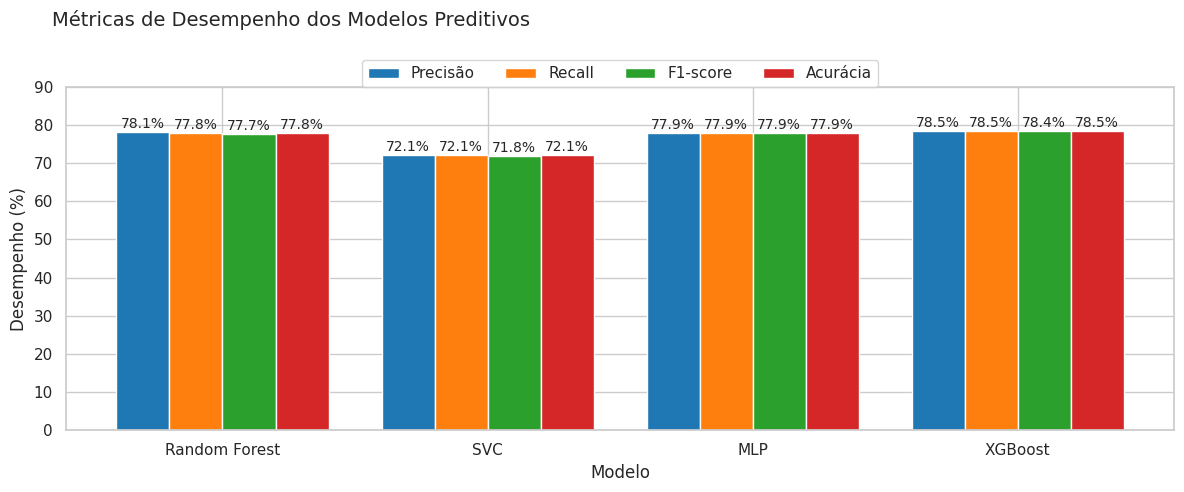

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns

# Dados da tabela
data = {
    "Modelo": ["Random Forest", "SVC", "MLP", "XGBoost"],
    "Precisão": [78.1, 72.1, 77.9, 78.5],
    "Recall": [77.8, 72.1, 77.9, 78.5],
    "F1-score": [77.7, 71.8, 77.9, 78.4],
    "Acurácia": [77.8, 72.1, 77.9, 78.5]
}

df = pd.DataFrame(data)

# Configuração do estilo
sns.set(style="whitegrid")
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

# Plotando o gráfico
fig, ax = plt.subplots(figsize=(12, 5))

bar_width = 0.2
index = np.arange(len(df["Modelo"]))

for i, metric in enumerate(["Precisão", "Recall", "F1-score", "Acurácia"]):
    bars = ax.bar(index + i * bar_width, df[metric], bar_width, label=metric, color=colors[i])
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.1f}%', xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3), textcoords="offset points", ha='center', fontsize=10)

# Configurações do gráfico
ax.set_xlabel('Modelo', fontsize=12)
ax.set_ylabel('Desempenho (%)', fontsize=12)
ax.set_xticks(index + 1.5 * bar_width)
ax.set_xticklabels(df["Modelo"])
ax.set_ylim(0, 90)

# Título alinhado à esquerda
plt.suptitle('Métricas de Desempenho dos Modelos Preditivos', x=0.05, ha='left', fontsize=14)

# Legenda abaixo do título
ax.legend(loc='upper center', bbox_to_anchor=(0.5, 1.1), ncol=4)

plt.tight_layout()
plt.show()


### Testes Combinações de PCA e Clusters

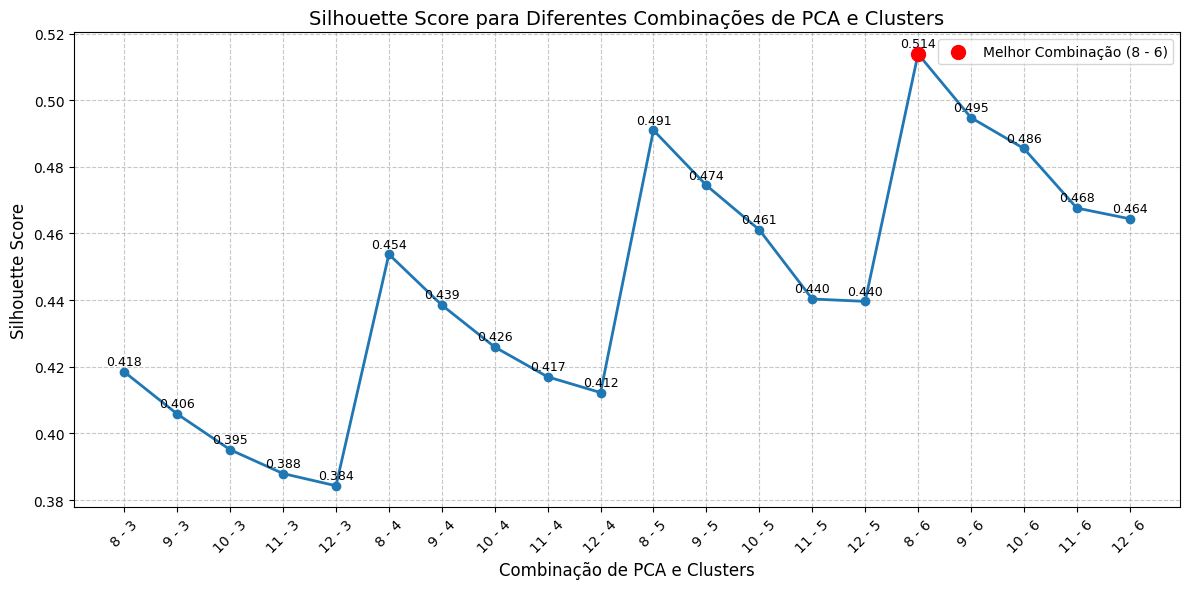

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

# Dados fornecidos
data = {
    "Quant. Testes": list(range(1, 21)),
    "PCA e Clusters": [
        "8 - 3", "9 - 3", "10 - 3", "11 - 3", "12 - 3",
        "8 - 4", "9 - 4", "10 - 4", "11 - 4", "12 - 4",
        "8 - 5", "9 - 5", "10 - 5", "11 - 5", "12 - 5",
        "8 - 6", "9 - 6", "10 - 6", "11 - 6", "12 - 6"
    ],
    "Silhouette Score": [
        0.4184541341561420, 0.4058176720386340, 0.3951115846218970, 0.3879508852973310, 0.3842854542460570,
        0.4537511199712430, 0.4385215556773700, 0.4259205423212190, 0.4169764446326590, 0.4122580466370080,
        0.4909819830446780, 0.4744328212101510, 0.4610974515588640, 0.4403358402768810, 0.4396218825506450,
        0.5138811018387510, 0.4947498840423600, 0.4855006761618310, 0.4676296448613900, 0.4644048459089640
    ]
}

df = pd.DataFrame(data)

# Criar o gráfico
plt.figure(figsize=(12, 6))
plt.plot(df["PCA e Clusters"], df["Silhouette Score"], marker='o', linestyle='-', linewidth=2, markersize=6)

# Adiciona os rótulos com 3 casas decimais
for i, txt in enumerate(df["Silhouette Score"]):
    plt.text(df["PCA e Clusters"][i], df["Silhouette Score"][i] + 0.002, f"{txt:.3f}",
             ha='center', fontsize=9)

plt.title('Silhouette Score para Diferentes Combinações de PCA e Clusters', fontsize=14)
plt.xlabel('Combinação de PCA e Clusters', fontsize=12)
plt.ylabel('Silhouette Score', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()

# Exibir o gráfico
plt.show()
